# Au–Cu phase diagram

The Au–Cu phase diagram from calphy free energies of an ACE potential fitted to LDA data. The phases are the fcc solid solution, the liquid and three ordered compounds (Au$_4$Cu$_2$, AuCu, AuCu$_3$).

landau fits a smooth free energy surface to each phase, and sharpens the phase boundaries and triple points after the first pass.

Saves `AuCu_Phasediagram_LDA.svg` and `.png`.

## Setup

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import landau as ld

warnings.simplefilter("ignore")

In [2]:
DATA = "CuAu_ACE_LDA_V4.pkl.gz"
OUT = "AuCu_Phasediagram_LDA.svg"

LABELS = {"fcc": "fcc", "lqd": "liquid", "au2cu": r"Au$_4$Cu$_2$", "aucu": "AuCu", "aucu3": r"AuCu$_3$"}
PHASE_COLOR = {"fcc": "#a1c9f4", "liquid": "#ffb482", r"Au$_4$Cu$_2$": "#8de5a1", "AuCu": "#ff9f9b",
               r"AuCu$_3$": "#d0bbff"}

T_MIN = 450.0
DT, MU = 4.0, np.linspace(-1.0, 0.85, 200)
MIN_C_WIDTH = 0.005

FIGSIZE = (7, 5.5)
AXES = (0.95 / 7, 0.75 / 5.5, 5.85 / 7, 4.6 / 5.5)  # the same plot area as the Mg-Ca figure
FONTSIZE = 15
DPI = 150

## Data

One row per phase and Cu concentration, each with free energies over a range of temperatures.

In [3]:
raw = pd.read_pickle(DATA)
raw = (raw.assign(n=raw.temperature.map(len)).sort_values("n", ascending=False)  # keep the longest sweep
          .drop_duplicates(["phase", "composition"]).drop(columns="n").sort_index())
raw.groupby("phase").composition.agg(["count", "min", "max"])

,count,min,max
phase,,,
au2cu,21,0.199942,0.399884
aucu,11,0.449942,0.550058
aucu3,11,0.700000,0.800000
fcc,51,0.000000,1.000000
lqd,51,0.000000,1.000000


## Phases

fcc and liquid use a CALPHAD-style surface. The ordered compounds use a surface built for a narrow free energy well around their composition.

In [4]:
def line(r):
    return ld.TemperatureDependentLinePhase(
        LABELS[r.phase], float(r.composition), np.asarray(r.temperature, float), np.asarray(r.free_energy, float),
        interpolator=ld.interpolate.SGTE(4),
    )


def solution(name, sub, num_coeffs, T_max):
    return ld.Surface2DInterpolatingPhase(
        LABELS[name], [line(r) for r in sub.itertuples()],
        surface_interpolator=ld.CalphadSurface2DInterpolator(
            num_coeffs=num_coeffs, terminal_sgte_order=4, coeff_poly_order=3
        ),
        maximum_extrapolation=0.05, add_entropy=False, temperature_range=(400.0, T_max),
    )


def ordered(name, sub, **opts):
    opts = dict(n_softplus=2, loss="soft_l1", max_nfev=4000, b_order=1, c_order=0, shared_knee=True) | opts
    return ld.Surface2DInterpolatingPhase(
        LABELS[name], [line(r) for r in sub.itertuples()],
        surface_interpolator=ld.SoftplusSurface2DInterpolator(**opts),
        concentration_range=(sub.composition.min() - 0.05, sub.composition.max() + 0.05), add_entropy=False,
    )


rows = {name: sub.sort_values("composition") for name, sub in raw.groupby("phase")}
T_max = float(max(np.max(t) for t in rows["fcc"].temperature))
phases = [
    solution("fcc", rows["fcc"], num_coeffs=3, T_max=T_max),
    solution("lqd", rows["lqd"], num_coeffs=5, T_max=T_max),
    ordered("au2cu", rows["au2cu"].query("composition > 0.275"), knee_bounds=(0.30, 0.37)),
    ordered("aucu", rows["aucu"], b_order=2),
    ordered("aucu3", rows["aucu3"]),
]

## Calculate

The `refine` argument adds extra points along phase boundaries and at triple points.

In [5]:
df = ld.calculate.calc_phase_diagram(
    phases, Ts=np.arange(T_MIN, T_max + 1, DT), mu=MU, keep_unstable=True,
    refine=[
        ld.refine.ClausiusClapeyronRefiner(dT_min=1, dT_max=15, dc_min=0.01, dc_max=0.05),
        ld.refine.DelaunayTripleRefiner(),
    ],
)
df.query("stable").groupby("phase").T.max().round(0)

phase
Au$_4$Cu$_2$     594.0
AuCu             732.0
AuCu$_3$         661.0
fcc             1463.0
liquid          1598.0
Name: T, dtype: float64

## Plot

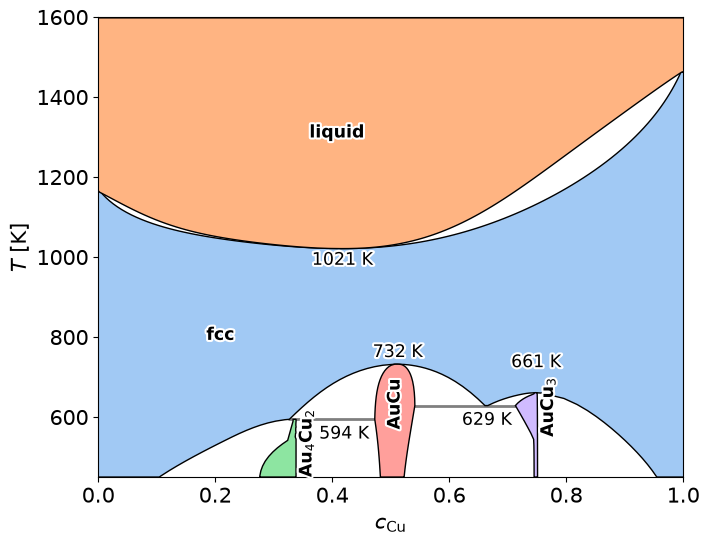

In [6]:
plt.rcParams.update({"font.size": FONTSIZE, "svg.fonttype": "none"})
fig = plt.figure(figsize=FIGSIZE)
ax = fig.add_axes(AXES)
ld.plot.plot_phase_diagram(
    df, element="Cu", color_override=PHASE_COLOR, triplepoints=True, transition_temperatures=True, ax=ax,
    poly_method=ld.poly.FastTsp(min_c_width=MIN_C_WIDTH),
)
ax.set_xlim(0, 1)
ax.set_ylim(T_MIN, T_max)

fig.savefig(OUT)
fig.savefig(OUT.replace(".svg", ".png"), dpi=DPI, transparent=True)